# Optimisation et évaluation des modèles

GridSearchCV compare le SVM, la Random Forest et la régression logistique.

In [13]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, classification_report, make_scorer)
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.svm import SVC

## 1. Chargement et nettoyage

In [14]:
data_path = Path("data/student_mental_health.csv")
if not data_path.exists():
    data_path = Path("../data/student_mental_health.csv")
df = pd.read_csv(data_path).drop_duplicates()
df = df.dropna(subset=["Mental_Health_Risk"]).drop(columns=["Student_ID"])
print(df.shape)

(2000, 16)


In [15]:
ranges = {"Age": (16, 100), "Year_of_Study": (1, 5), "Sleep_Hours": (0, 24),
          "Study_Hours_Per_Week": (0, 44), "GPA": (0, 4),
          "Social_Media_Hours": (0, 24), "Screen_Time_Hours": (0, 24),
          "Financial_Stress": (0, 10), "Family_Support": (0, 10),
          "Attendance_Rate": (0, 100)}
for col, (low, high) in ranges.items():
    df.loc[(df[col] < low) | (df[col] > high), col] = np.nan

## 2. Partage et prétraitement

Les transformations sont réapprises à l’intérieur de chaque pli de validation. Le rappel « High » est utilisé pour rechercher les paramètres, afin de limiter les faux négatifs.

In [16]:
X = df.drop(columns=["Mental_Health_Risk"])
y = df["Mental_Health_Risk"]
x_train, x_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
num_cols = x_train.select_dtypes(include="number").columns.tolist()
onehot_cols = ["Gender", "Part_Time_Job", "Previous_Mental_Health_History"]
ordinal_cols = ["Physical_Activity", "Diet_Quality"]

In [17]:
class IQRClipper(BaseEstimator, TransformerMixin):
    def fit(self, X, y=None):
        q1, q3 = np.percentile(X, [25, 75], axis=0)
        self.low_ = q1 - 1.5 * (q3 - q1)
        self.high_ = q3 + 1.5 * (q3 - q1)
        return self

    def transform(self, X):
        return np.clip(X, self.low_, self.high_)

In [18]:
num_pipe = Pipeline([("imputer", SimpleImputer(strategy="median")),
                     ("outliers", IQRClipper()), ("scaler", StandardScaler())])
cat_pipe = Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                     ("encoder", OneHotEncoder(handle_unknown="ignore"))])
ord_pipe = Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                     ("encoder", OrdinalEncoder(categories=[["Low", "Moderate", "High"],
                       ["Poor", "Average", "Good"]], handle_unknown="use_encoded_value",
                       unknown_value=-1))])

In [19]:
preprocessor = ColumnTransformer([
    ("num", num_pipe, num_cols),
    ("onehot", cat_pipe, onehot_cols),
    ("ordinal", ord_pipe, ordinal_cols)
])

## 3. Recherche des hyperparamètres

In [20]:
models = {
    "SVM": (SVC(probability=True, random_state=42), {"model__C": [0.1, 1, 10]}),
    "Random Forest": (RandomForestClassifier(random_state=42),
                      {"model__n_estimators": [100, 200], "model__max_depth": [None, 10]}),
    "Régression Logistique": (LogisticRegression(max_iter=1000, random_state=42),
                              {"model__C": [0.1, 1, 10]})
}
high_recall = make_scorer(recall_score, labels=["High"], average="macro", zero_division=0)

In [21]:
searches = {}
for name, (model, params) in models.items():
    pipe = Pipeline([("preparation", preprocessor), ("model", model)])
    search = GridSearchCV(pipe, params, scoring=high_recall, cv=3, n_jobs=-1)
    search.fit(x_train, y_train)
    searches[name] = search
    print(name, search.best_params_)

C:\Users\Olaya\AppData\Roaming\Python\Python313\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


SVM {'model__C': 10}
Random Forest {'model__max_depth': None, 'model__n_estimators': 200}
Régression Logistique {'model__C': 0.1}


## 4. Comparaison sur le jeu de test

In [22]:
rows = []
for name, search in searches.items():
    model = search.best_estimator_
    pred = model.predict(x_test)
    proba = model.predict_proba(x_test)
    rows.append({"Modèle": name, "Rappel High (CV)": search.best_score_,
        "Accuracy": accuracy_score(y_test, pred),
        "Précision macro": precision_score(y_test, pred, average="macro", zero_division=0),
        "Rappel macro": recall_score(y_test, pred, average="macro", zero_division=0),
        "Rappel High": recall_score(y_test, pred, labels=["High"], average="macro", zero_division=0),
        "F1 macro": f1_score(y_test, pred, average="macro", zero_division=0),
        "ROC-AUC OVR": roc_auc_score(y_test, proba, labels=model.classes_,
                                       multi_class="ovr", average="macro")})

In [23]:
results = pd.DataFrame(rows).set_index("Modèle").sort_values("Rappel High", ascending=False)
print(results.round(3))
print("Modèle retenu :", results.index[0])

                       Rappel High (CV)  Accuracy  Précision macro  \
Modèle                                                               
Régression Logistique             0.812     0.755            0.755   
SVM                               0.772     0.715            0.711   
Random Forest                     0.809     0.708            0.706   

                       Rappel macro  Rappel High  F1 macro  ROC-AUC OVR  
Modèle                                                                   
Régression Logistique         0.754        0.816     0.755        0.913  
SVM                           0.714        0.765     0.712        0.876  
Random Forest                 0.707        0.757     0.707        0.857  
Modèle retenu : Régression Logistique



 SVM — meilleurs paramètres : {'model__C': 10}
              precision    recall  f1-score   support

        High       0.76      0.76      0.76       136
         Low       0.78      0.83      0.80       132
      Medium       0.59      0.55      0.57       132

    accuracy                           0.71       400
   macro avg       0.71      0.71      0.71       400
weighted avg       0.71      0.71      0.71       400



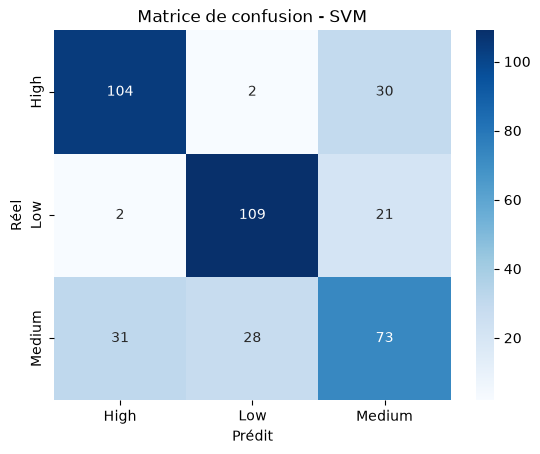


 Random Forest — meilleurs paramètres : {'model__max_depth': None, 'model__n_estimators': 200}
              precision    recall  f1-score   support

        High       0.75      0.76      0.75       136
         Low       0.80      0.80      0.80       132
      Medium       0.58      0.57      0.57       132

    accuracy                           0.71       400
   macro avg       0.71      0.71      0.71       400
weighted avg       0.71      0.71      0.71       400



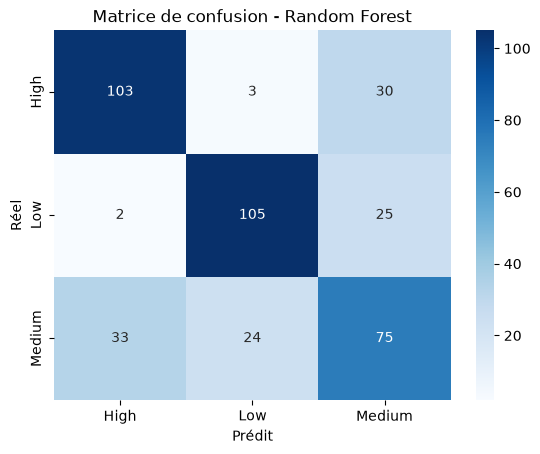


 Régression Logistique — meilleurs paramètres : {'model__C': 0.1}
              precision    recall  f1-score   support

        High       0.82      0.82      0.82       136
         Low       0.82      0.81      0.81       132
      Medium       0.63      0.64      0.63       132

    accuracy                           0.76       400
   macro avg       0.75      0.75      0.75       400
weighted avg       0.76      0.76      0.76       400



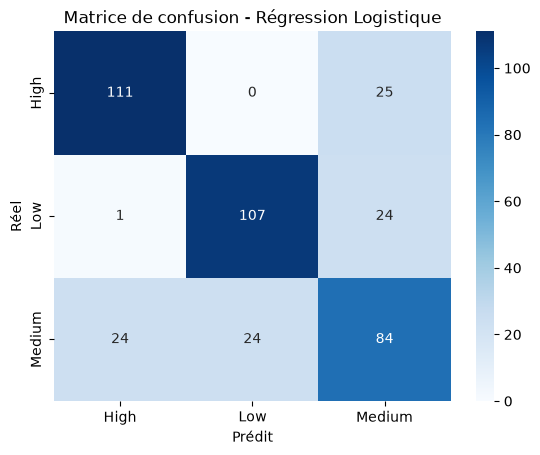

In [24]:
for name, search in searches.items():
    model = search.best_estimator_
    pred = model.predict(x_test)
    labels = model.classes_
    print("\n", name, "— meilleurs paramètres :", search.best_params_)
    print(classification_report(y_test, pred, zero_division=0))
    sns.heatmap(confusion_matrix(y_test, pred, labels=labels), annot=True, fmt="d",
                xticklabels=labels, yticklabels=labels, cmap="Blues")
    plt.title("Matrice de confusion - " + name)
    plt.xlabel("Prédit")
    plt.ylabel("Réel")
    plt.show()